# Week 10.2 - One-dimensional kinetic shocks: BGK, Shakhov, PINNs and DVM

[Open in Colab](https://colab.research.google.com/github/Ehsan-Roohi/FlowMLLab/blob/main/notebooks/week10_2/W10_2_BGK_Shakhov_Shock_PINN_DVM.ipynb)
· [Lecture](../../lectures/week10_2_bgk_shakhov_shock_pinn_dvm.pdf)
· [Setup](README.md) · [Paper, revised 13 November 2026](https://arxiv.org/abs/2605.29211v2)

**Question:** when density and temperature look right, can heat flux, stress
or fourth-order moments still be wrong? Compute collision moments on CPU,
then answer with the paper's actual matched PINN/DVM profiles.

Prerequisites: Week 2 data roles, Week 3 Maxwellians and moments, Week 8 shock
jumps, and Week 10 profile validation. The lecture introduces the PINN
residual; prior completion of the full Week 13 research audit is optional.

**Two execution modes are kept distinct.** Tables B-D are fresh CPU
calculations. Tables E-G re-evaluate saved scientific predictions.
Full historical network training is a separate research workflow.
All variables are nondimensional, with gas constant $R_g=1$ and
$\gamma=5/3$. One spatial dimension still has **three molecular velocity
components**. Do not replace this model with a scalar Burgers equation.

In [1]:
# FLOWMLLAB_COLAB_BOOTSTRAP_V1
from pathlib import Path
import sys, subprocess, time, json
START = time.perf_counter()
ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents, Path('/content/FlowMLLab')]
             if (p/'flowmllab/kinetic_shock.py').is_file()), None)
if ROOT is None:
    candidate = Path('/content/FlowMLLab') if Path('/content').is_dir() else Path.cwd()/'FlowMLLab'
    if candidate.exists():
        raise RuntimeError('Save your own work and update the existing checkout to a revision with Week 10.2. This cell never overwrites it.')
    subprocess.run(['git','clone','--depth','1','--filter=blob:none','--sparse',
                    'https://github.com/Ehsan-Roohi/FlowMLLab.git',str(candidate)],check=True)
    subprocess.run(['git','-C',str(candidate),'sparse-checkout','set',
                    'flowmllab','data/week10_2_kinetic_shock'],check=True)
    subprocess.run([sys.executable,'-m','pip','install','-q','-e',str(candidate)],check=True)
    ROOT = candidate
if str(ROOT) not in sys.path: sys.path.insert(0,str(ROOT))
import numpy as np
import pandas as pd
from IPython import get_ipython
get_ipython().run_line_magic('matplotlib', 'inline')
import matplotlib.pyplot as plt
from IPython.display import display
from flowmllab import kinetic_shock as ks
print('Mode: fresh CPU collision/moment calculations + retained PINN/DVM rescoring.')
print('Data source commit:',ks.UPSTREAM_COMMIT)
print('No neural training or spatial shock solve is launched by Run All.')

Mode: fresh CPU collision/moment calculations + retained PINN/DVM rescoring.
Data source commit: add5388f7da5f7eace95fff97d34d6ed58b90169
No neural training or spatial shock solve is launched by Run All.


## 1. Table A - Case and data-role registry

Check the collision model, relaxation law, time/domain and reference role
before comparing two curves. A stationary Mach-2 shock is a different
problem from the short-time smoothed shock tube. The loader checks hashes,
grid coordinates and case identities; it does not fit shifts or rescale a
prediction to improve its score. Read the data-assisted comparison's
metadata for its explicit common-grid interpolation.

In [2]:
manifest = ks.load_manifest()
registry = []
for case_id in ks.available_cases():
    case = ks.load_case(case_id)
    registry.append(dict(case=case_id, problem=case.metadata['problem'],
        model=case.metadata['collision_model'], tau=case.metadata.get('tau_law'),
        rows=len(case.x), xmin=case.x[0], xmax=case.x[-1],
        methods=', '.join(case.methods)))
table_A = pd.DataFrame(registry)
print('Table A: verified retained cases; these are not newly trained networks')
display(table_A)

Table A: verified retained cases; these are not newly trained networks


,case,problem,model,tau,rows,xmin,xmax,methods
0,tube_bgk,transient_shock_tube,BGK,constant_1,3200,-0.499844,0.499844,"parent, final, reference"
1,tube_shakhov,transient_shock_tube,Shakhov,constant_1,3200,-0.499844,0.499844,"parent, final, reference"
2,m2_seed141001_adam20000,steady_normal_shock,Shakhov,1/rho,81,-10.000000,10.000000,"prediction, reference"
3,m2_seed141001_ssb500,steady_normal_shock,Shakhov,1/rho,81,-10.000000,10.000000,"prediction, reference"
4,m2_seed141001_fixed500,steady_normal_shock,Shakhov,1/rho,81,-10.000000,10.000000,"prediction, reference"
5,m2_seed141002_adam20000,steady_normal_shock,Shakhov,1/rho,81,-10.000000,10.000000,"prediction, reference"
6,m2_seed141002_ssb500,steady_normal_shock,Shakhov,1/rho,81,-10.000000,10.000000,"prediction, reference"
7,m2_seed141002_fixed500,steady_normal_shock,Shakhov,1/rho,81,-10.000000,10.000000,"prediction, reference"
8,m2_seed141003_adam20000,steady_normal_shock,Shakhov,1/rho,81,-10.000000,10.000000,"prediction, reference"
9,m2_seed141003_ssb500,steady_normal_shock,Shakhov,1/rho,81,-10.000000,10.000000,"prediction, reference"


## 2. Table B - Jump states and the correct steady fluxes

Upstream $\rho_1=T_1=1$ and $u_1=M\sqrt{5/3}$. For a monatomic normal shock,
$$\rho_2=\frac{4M^2}{M^2+3},\quad u_2=\frac{u_1}{\rho_2},\quad
T_2=\frac{5M^2-1}{4\rho_2}.$$
The kinetic stress is $\sigma=\int(c_x^2-c^2/3)f\,d\mathbf v$, and
$q=\frac12\int c^2c_x f\,d\mathbf v$, where $\mathbf c=\mathbf v-u\mathbf e_x$.
Preserve both signs. A steady solution conserves
$$J_m=\rho u,\quad J_p=\rho u^2+\rho T+\sigma,\quad
J_E=\frac12\rho u^3+\frac52\rho Tu+u\sigma+q.$$
Equilibrium endpoints have $q=\sigma=0$. The same spatially constant-flux
test does **not** apply to the transient shock tube.

In [3]:
MACH = 2.0  # Exercise 1: also try 1.5 and 3.0, one case at a time.
states = ks.jump_states(MACH)
flux_rows = []
for side in ('upstream','downstream'):
    s = states[side]
    flux = ks.stationary_fluxes(s['rho'],s['u'],s['T'],0.0,0.0)
    flux_rows.append({'side':side, **s, **{k:float(v) for k,v in flux.items()}})
table_B = pd.DataFrame(flux_rows)
print('Table B: fresh Rankine-Hugoniot states and fluxes')
display(table_B)
assert np.allclose(table_B.iloc[0][['mass','momentum','energy']].astype(float),
                   table_B.iloc[1][['mass','momentum','energy']].astype(float),rtol=1e-12)

Table B: fresh Rankine-Hugoniot states and fluxes


,side,rho,u,T,mass,momentum,energy
0,upstream,1.000000,2.581989,1.000000,2.581989,7.666667,15.061602
1,downstream,2.285714,1.129620,2.078125,2.581989,7.666667,15.061602


## 3. Table C - Which moments can the reduced distributions determine?

$g=\int f\,dv_y dv_z$, $h=\int(v_y^2+v_z^2)f\,dv_y dv_z$ and
$k=\int(v_y^2+v_z^2)^2f\,dv_y dv_z$. There is **no factor one-half in $h$**.
For $c=v_x-u$, all following integrals are over $v_x$:
$$3\rho T=\int(c^2g+h),\quad q=\frac12\int(c^3g+ch),\quad
\sigma=\frac13\int(2c^2g-h).$$
$$R=\frac13\int(2c^4g+c^2h-k)-7T\sigma,\qquad
\Delta=\int(c^4g+2c^2h+k)-15\rho T^2.$$
$S=R+\Delta/3$ is a derived ninth diagnostic. Eight-moment supervision
means $\rho,u,T,q,\sigma,m,R,\Delta$, not eight independent entries plus $S$.

The next calculation compares two **positive** full distributions with
the same $g,h$. A has a transverse Gaussian temperature 1; B mixes
transverse temperatures 0.5 and 1.5 equally. Both have $g=N(0,1)$ and
$h=2g$, but $k_A=8g$ and $k_B=10g$. Predict $R,\Delta,S$ before running.

In [4]:
counter = ks.transverse_counterexample(order=64,cutoff=9)
fields = ['rho','u','T','q','sigma','m','R','Delta','S']
table_C = pd.DataFrame([{'case':name,**{f:counter[name][f] for f in fields}}
                        for name in ('A','B')])
print('Table C: same g and h; different R and Delta')
display(table_C)
assert np.isclose(counter['B']['R'],-2/3,atol=1e-9)
assert np.isclose(counter['B']['Delta'],2,atol=1e-9)
assert np.isclose(counter['B']['S'],0,atol=1e-9)
print('Quantities available without k:',list(counter['without_k']))

Table C: same g and h; different R and Delta


,case,rho,u,T,q,sigma,m,R,Delta,S
0,A,1.0,-2.775558e-17,1.0,-5.551115e-17,-2.428613e-16,-1.387779e-17,-1.075529e-15,-3.552714e-15,-8.881784e-16
1,B,1.0,-2.775558e-17,1.0,-5.551115e-17,-2.428613e-16,-1.387779e-17,-6.666667e-01,2.000000e+00,-8.881784e-16


Quantities available without k: ['rho', 'u', 'T', 'q', 'sigma', 'm', 'S']


## 4. Table D - A fresh CPU collision experiment

Both models solve $\partial_t f+v_x\partial_x f=(\mathcal T-f)/\tau$.
BGK uses the Maxwellian $\mathcal M$. Shakhov uses
$$\mathcal T_S=\mathcal M\left[1+
\frac{(1-\Pr)q c_x}{5\rho T^2}\left(\frac{c^2}{T}-5\right)\right].$$
The fresh calculation uses the positive mixture
$0.7\mathcal M(1,0.8,0.7)+0.3\mathcal M(1,-1.2,1.4)$, with zero transverse
mean velocities. Its exact infinite-domain moments are
$(\rho,u,T,\sigma,q)=(1,0.2,1.19,0.56,-1.071)$.

Integrate the collision term with tensor Gauss-Legendre quadrature on
$[-V,V]^3$. It should conserve mass, momentum and energy; stress relaxes
at $-\sigma/\tau$ and heat flux at $-\Pr q/\tau$. Order and cutoff are
different errors. The Shakhov target can have negative tails: count them
without clipping, and check whether their mass is significant. This
homogeneous experiment tests collision physics; it is not a shock solve.

In [5]:
COLLISION_ORDER = 32
VELOCITY_CUTOFF = 8.0
PRANDTL = 2/3
TAU = 1.0
fresh = ks.collision_experiment(order=COLLISION_ORDER,cutoff=VELOCITY_CUTOFF,
                                 Pr=PRANDTL,tau=TAU)
collision_rows = []
for model,d in fresh['diagnostics'].items():
    collision_rows.append(dict(model=model,order=COLLISION_ORDER,cutoff=VELOCITY_CUTOFF,
        invariant_rate_max=float(np.max(np.abs(d['invariant_rate']))),
        stress_rate=d['stress_rate'],expected_stress_rate=d['expected_stress_rate'],
        q_rate=d['q_rate'],expected_q_rate=d['expected_q_rate'],
        minimum_target=d['minimum_target'],negative_nodes=d['negative_nodes'],
        negative_mass=d['negative_mass']))
table_D = pd.DataFrame(collision_rows)
print('Fresh mixture moments:',fresh['moments'])
print('Table D: measured collision moments, without clipping or correction')
display(table_D)
assert fresh['input_positive'] and not fresh['is_shock_solution']
assert all(not d['clipping_applied'] for d in fresh['diagnostics'].values())

Fresh mixture moments: {'rho': 0.9999999945705185, 'u': 0.20000000475989296, 'T': 1.1900000006533638, 'q': -1.0709995193004147, 'sigma': 0.5599999263039803, 'm': -0.2687996735003309, 'R': 0.8287963185688785, 'Delta': 3.9626912571725974, 'S': 2.1496934042930773, 'transverse_mean': array([1.53515437e-19, 5.41272058e-18])}
Table D: measured collision moments, without clipping or correction


,model,order,cutoff,invariant_rate_max,stress_rate,expected_stress_rate,q_rate,expected_q_rate,minimum_target,negative_nodes,negative_mass
0,BGK,32,8.0,2.722093e-11,-0.56,-0.56,1.071,1.071,1.801870e-37,0,0.000000
1,Shakhov,32,8.0,2.279471e-10,-0.56,-0.56,0.714,0.714,-4.224607e-05,15008,0.000928


In [6]:
# Exercise 3: change one parameter at a time; retain every measured row.
QUADRATURE_CASES = [(12,8.0),(20,8.0),(32,8.0),(32,4.0),(32,6.0)]
sweep = []
for n,V in QUADRATURE_CASES:
    t0 = time.perf_counter()
    trial = ks.collision_experiment(order=n,cutoff=V,Pr=PRANDTL,tau=TAU)
    for model,d in trial['diagnostics'].items():
        sweep.append(dict(order=n,cutoff=V,model=model,
            density_error=abs(trial['moments']['rho']-1),
            heat_flux_error=abs(trial['moments']['q']+1.071),
            invariant_rate_max=np.max(np.abs(d['invariant_rate'])),
            q_rate_error=d['q_rate_absolute_error'],seconds=time.perf_counter()-t0))
print('Table D continuation: quadrature and velocity-tail sensitivity')
display(pd.DataFrame(sweep))

Table D continuation: quadrature and velocity-tail sensitivity


,order,cutoff,model,density_error,heat_flux_error,invariant_rate_max,q_rate_error,seconds
0,12,8.0,BGK,6.291695e-02,1.176378e-01,5.867425e-02,3.727625e-02,0.001943
1,12,8.0,Shakhov,6.291695e-02,1.176378e-01,4.972951e-02,4.117356e-02,0.001948
2,20,8.0,BGK,2.751551e-04,3.346844e-03,6.042200e-05,8.216204e-05,0.008606
3,20,8.0,Shakhov,2.751551e-04,3.346844e-03,3.590983e-05,2.909572e-04,0.008612
4,32,8.0,BGK,5.429482e-09,4.806996e-07,2.722093e-11,1.155098e-10,0.031652
5,32,8.0,Shakhov,5.429482e-09,4.806996e-07,2.279471e-10,2.371837e-09,0.031659
6,32,4.0,BGK,3.173886e-03,1.125381e-01,7.271127e-03,6.398998e-03,0.147344
7,32,4.0,Shakhov,3.173886e-03,1.125381e-01,3.412460e-03,2.549683e-02,0.147357
8,32,6.0,BGK,7.702231e-06,9.161697e-04,2.751714e-06,5.159510e-06,0.024628
9,32,6.0,Shakhov,7.702231e-06,9.161697e-04,4.861890e-06,5.786185e-05,0.024637


## 5. Reading a kinetic PINN result

The source's transient network predicts **source-state** density, velocity
and temperature (also heat flux for Shakhov). It does not directly output
the nine plotted moments. The source state forms a collision target;
a characteristic integral reconstructs the distribution, whose velocity
integrals give the reported moments. Self-consistency between these two
routes matters. Along an interior characteristic with constant relaxation
time, before it meets an inflow boundary,
$$f(t,x,\mathbf v)=e^{-t/\tau}f_0(x-v_xt,\mathbf v)
+\frac1\tau\int_0^t e^{-(t-s)/\tau}
\mathcal T_\theta(s,x-v_x(t-s),\mathbf v)\,ds.$$
Here $\theta$ are network parameters and $s$ is integration time. If a
characteristic enters through a boundary, start the integral at that
entry time and use its prescribed incoming distribution. The stationary
paper cases use different distribution/correction parameterizations and
differential residual checks. Their losses are not interchangeable.

Separate physics/self-consistency, initial/incoming conditions and optional
observed-moment terms. A small weighted total loss is not a common
accuracy unit, nor proof of accurate unobserved moments.

We now evaluate **stored** fields. For field $a$ and matched reference
$a_{ref}$, use a spatially weighted norm:
$$E_a=100\sqrt{\frac{\int(a-a_{ref})^2dx}{\int a_{ref}^2dx}}.$$
Integrals use trapezoidal weights on the declared comparison nodes.
Plot the signed discrepancy $a-a_{ref}$ as well. Never divide pointwise
by $a_{ref}(x)$ at a zero crossing. A zero reference norm makes relative
error undefined; report an explicit physical scale instead.

In [7]:
FIELD_LABELS = {'rho':r'$\rho$','u':r'$u$','T':r'$T$','q':r'$q_x$',
                'sigma':r'$\sigma_{xx}$','m':r'$m_{xxx}$','R':r'$R_{xx}$',
                'Delta':r'$\Delta$','S':r'$S_{xx}$'}
def selected_methods(case,include_intermediates=False):
    if 'five_field_S0' in case.methods and not include_intermediates:
        return [m for m in ('five_field_S0','data_assisted','equation_trained') if m in case.methods]
    return [m for m in case.methods if m!='reference']
def score_profiles(case,include_intermediates=False):
    rows = []
    for method in selected_methods(case,include_intermediates):
        for field in case.columns:
            e = ks.profile_metrics(case.x,case.field(method,field),case.field('reference',field))
            rows.append(dict(method=method,field=field,E_percent=e['relative_l2_percent']))
    return pd.DataFrame(rows)
def plot_profiles(case,fields=('rho','u','T','q','sigma','m','R','Delta','S')):
    fields = [f for f in fields if f in case.columns]
    rows = (len(fields)+2)//3
    fig,axes = plt.subplots(rows,3,figsize=(12,2.7*rows+0.6),squeeze=False)
    palette = ['#2355b5','#c52a32','#16834b','#8b4f9e']
    methods = ['reference']+selected_methods(case)
    for ax,field in zip(axes.flat,fields):
        for i,method in enumerate(methods):
            ax.plot(case.x,case.field(method,field),label=method,
                    color='black' if i==0 else palette[(i-1)%4],
                    ls='-' if i==0 else ['--','-.',':','-'][(i-1)%4],lw=1.7)
        ax.set(xlabel='x',ylabel=FIELD_LABELS[field],xlim=(case.x[0],case.x[-1]))
        ax.grid(alpha=.18)
    for ax in list(axes.flat)[len(fields):]: ax.set_visible(False)
    handles,labels = axes.flat[0].get_legend_handles_labels()
    fig.legend(handles,labels,loc='upper center',ncol=min(3,len(methods)),frameon=False)
    fig.tight_layout(rect=(0,0,1,.9),h_pad=1)
    plt.show()

## 6. Table E - Short-time BGK and Shakhov tubes

These two saved cases share $x\in[-0.5,0.5]$, $t_f=0.02$ and
$\tau=\mathrm{Kn}=1$. Their Maxwellian initial macros interpolate between
$(1,0,1)$ and $(0.125,0,0.8)$ with $H=(1+\tanh20x)/2$. Only incoming
boundary populations are prescribed. This is a smoothed kinetic Riemann
problem, not a discontinuous Euler Sod result.

The maximum collision weight over this short interval is
$1-e^{-t_f/\tau}\approx0.0198$. Interpret differences as a predominantly
short-time transport test. Compare each PINN with its own collision-model
DVM. Do not swap the BGK and Shakhov reference columns.

Table E-BGK: stored profiles rescored against matched DVM


method,final,parent
field,,
Delta,1.397578,1.401627
R,1.714456,1.717941
S,1.575858,1.579266
T,0.009234,0.009332
m,0.826315,0.829315
q,0.410026,0.410616
rho,0.009606,0.009529
sigma,0.360440,0.356950
u,0.204188,0.196289


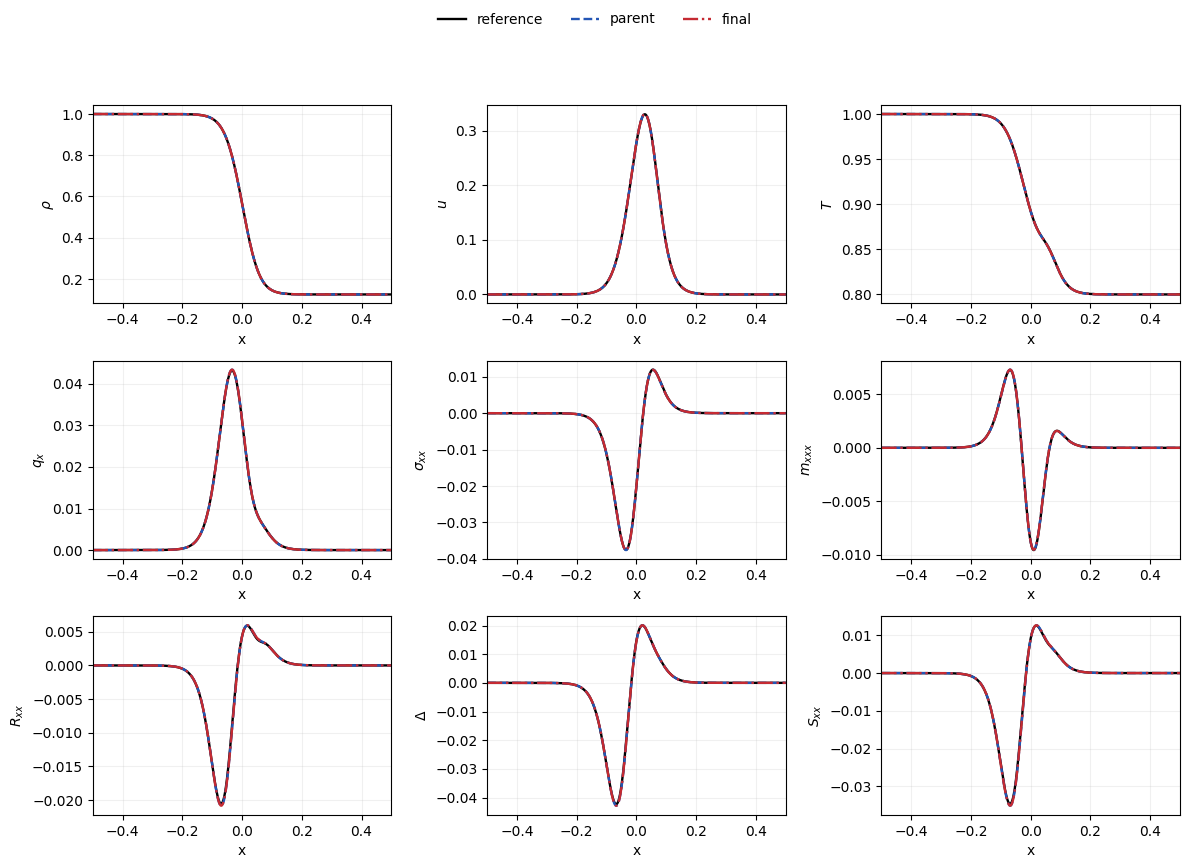

In [8]:
tube_bgk = ks.load_case('tube_bgk')
print('Table E-BGK: stored profiles rescored against matched DVM')
display(score_profiles(tube_bgk).pivot(index='field',columns='method',values='E_percent'))
plot_profiles(tube_bgk)

Table E-Shakhov: stored profiles rescored against matched DVM


method,final,parent
field,,
Delta,1.397872,1.397892
R,1.712494,1.713623
S,1.574836,1.575441
T,0.009186,0.009071
m,0.828417,0.826831
q,0.410055,0.412102
rho,0.009592,0.009587
sigma,0.360561,0.356830
u,0.202919,0.202718


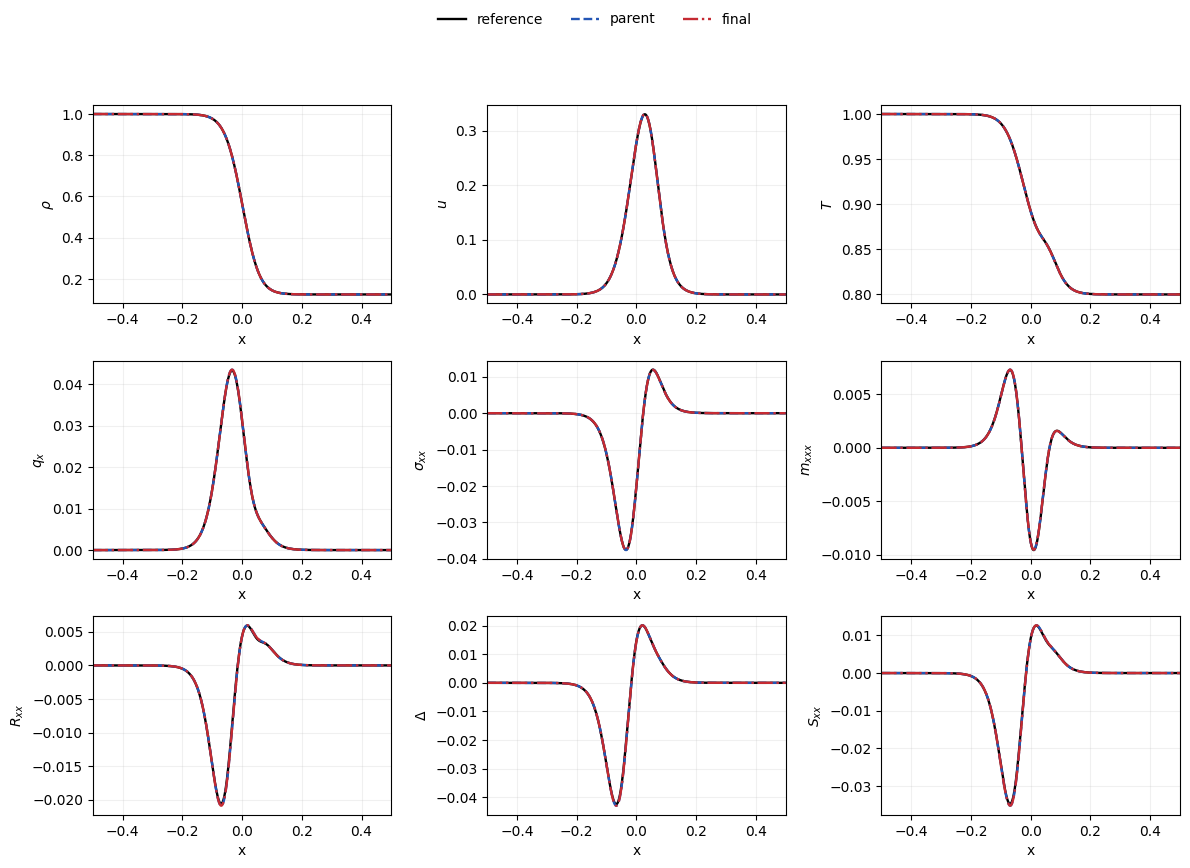

In [9]:
tube_shakhov = ks.load_case('tube_shakhov')
print('Table E-Shakhov: stored profiles rescored against matched DVM')
display(score_profiles(tube_shakhov).pivot(index='field',columns='method',values='E_percent'))
plot_profiles(tube_shakhov)

## 7. Table F - Independent stationary Mach-2 runs

These are Shakhov shocks with $\Pr=2/3$ and $\tau=1/\rho$.
Three initializations (141001, 141002, 141003) were retained at Adam,
SSB and split-half SSB stages. The stages change objective/quadrature and
cumulative work: this is a recorded optimization path, not an equal-budget
optimizer ranking. Compare heat flux and stress separately.

The source's final runs pass flux, phase, quadrature and positive-macro
checks, but fail tail and projection checks; two also fail kinetic residual
checks. Small conserved-flux defects do not certify accurate distributions.

In [10]:
stage_rows = []
for seed in (141001,141002,141003):
    for stage in ('adam20000','ssb500','fixed500'):
        case = ks.load_case(f'm2_seed{seed}_{stage}')
        method = next(m for m in case.methods if m!='reference')
        row = {'seed':seed,'stage':stage}
        for field in ('q','sigma'):
            row[field+'_error_percent'] = ks.profile_metrics(
                case.x,case.field(method,field),case.field('reference',field))['relative_l2_percent']
        stage_rows.append(row)
table_F = pd.DataFrame(stage_rows)
print('Table F: all individual-seed errors')
display(table_F)
print('Mean individual-seed errors, not the error of a seed-mean curve')
display(table_F.groupby('stage',sort=False)[['q_error_percent','sigma_error_percent']].mean())

Table F: all individual-seed errors


,seed,stage,q_error_percent,sigma_error_percent
0,141001,adam20000,20.380610,17.616425
1,141001,ssb500,1.823039,0.865667
2,141001,fixed500,1.106272,1.286008
3,141002,adam20000,19.846172,17.227810
4,141002,ssb500,2.206728,1.113822
5,141002,fixed500,0.990652,1.281321
6,141003,adam20000,20.334553,14.901372
7,141003,ssb500,2.308466,1.266850
8,141003,fixed500,1.015099,1.256074


Mean individual-seed errors, not the error of a seed-mean curve


,q_error_percent,sigma_error_percent
stage,,
adam20000,20.187111,16.581869
ssb500,2.112744,1.082113
fixed500,1.037341,1.274468


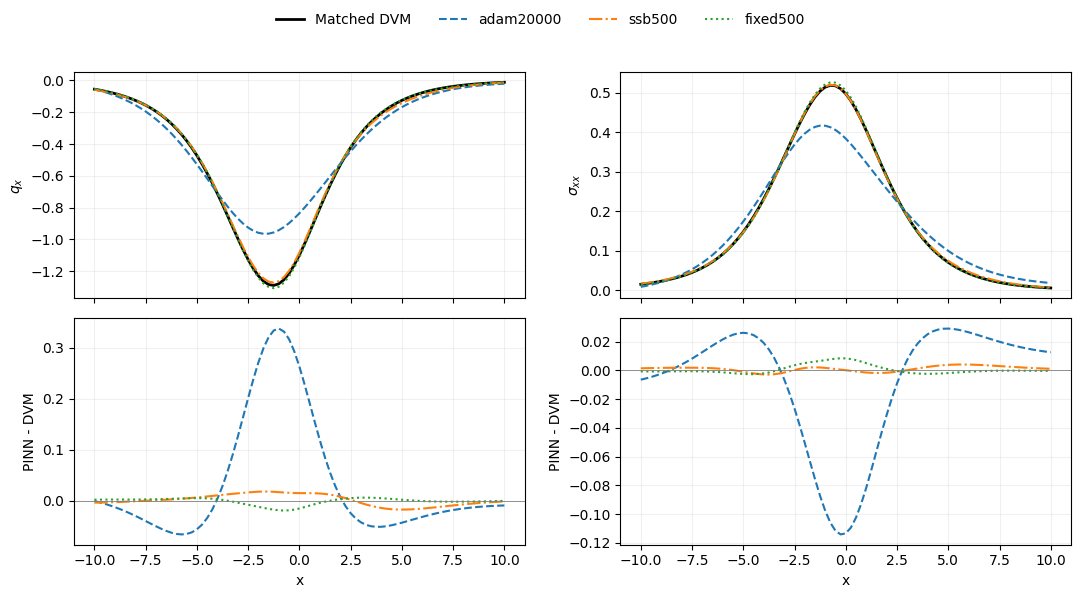

In [11]:
SEED_TO_VIEW = 141001  # Repeat with 141002 and 141003.
fig,axes = plt.subplots(2,2,figsize=(11,6),sharex=True)
for j,field in enumerate(('q','sigma')):
    for i,stage in enumerate(('adam20000','ssb500','fixed500')):
        case = ks.load_case(f'm2_seed{SEED_TO_VIEW}_{stage}')
        method = next(m for m in case.methods if m!='reference')
        ref,pred = case.field('reference',field),case.field(method,field)
        if i==0: axes[0,j].plot(case.x,ref,'k-',label='Matched DVM',lw=2)
        axes[0,j].plot(case.x,pred,label=stage,ls=['--','-.',':'][i])
        axes[1,j].plot(case.x,pred-ref,ls=['--','-.',':'][i])
    axes[0,j].set_ylabel(FIELD_LABELS[field])
    axes[1,j].set(xlabel='x',ylabel='PINN - DVM')
    axes[1,j].axhline(0,color='0.5',lw=.6)
for ax in axes.flat: ax.grid(alpha=.18)
fig.legend(*axes[0,0].get_legend_handles_labels(),loc='upper center',ncol=4,frameon=False)
fig.tight_layout(rect=(0,0,1,.91)); plt.show()

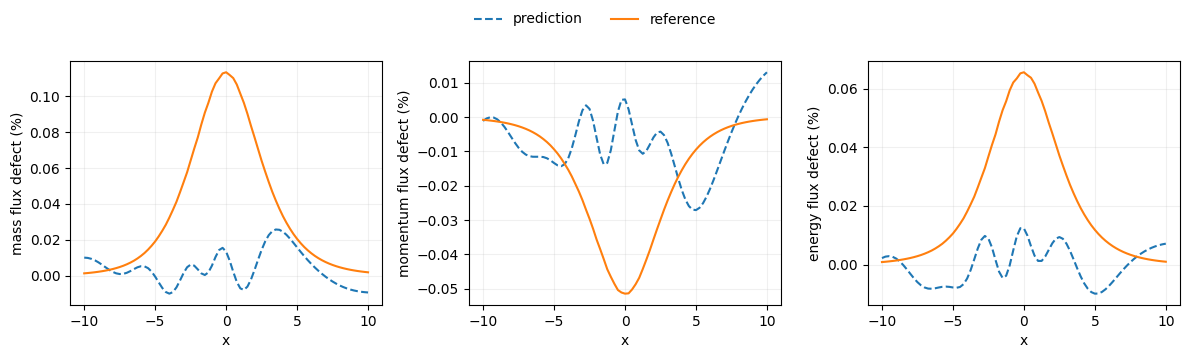

In [12]:
case = ks.load_case(f'm2_seed{SEED_TO_VIEW}_fixed500')
method = next(m for m in case.methods if m!='reference')
upstream = ks.jump_states(2)['upstream']
targets = ks.stationary_fluxes(upstream['rho'],upstream['u'],upstream['T'],0,0)
fig,axes = plt.subplots(1,3,figsize=(12,3.6))
for source,style in ((method,'--'),('reference','-')):
    fluxes = ks.stationary_fluxes(*(case.field(source,f) for f in ('rho','u','T','q','sigma')))
    for ax,key in zip(axes,('mass','momentum','energy')):
        ax.plot(case.x,100*(fluxes[key]/targets[key]-1),style,label=source)
        ax.set(xlabel='x',ylabel=key+' flux defect (%)')
        ax.grid(alpha=.18)
fig.legend(*axes[0].get_legend_handles_labels(),loc='upper center',ncol=2,frameon=False)
fig.tight_layout(rect=(0,0,1,.88)); plt.show()

## 8. Table G - Moment supervision and its reference-data roles

Compare the equation-trained BGK result, the five-field state S0 and
the final eight-moment state against the **same 6400-cell DVM reference**
on the declared common-overlap nodes. The paper's published comparison
uses 401 nodes; this teaching extract excludes any endpoint outside the
reference cell centres, rather than extrapolating. The metadata records
the exact retained count and interpolation policy, so its recomputed
values need not equal the paper's endpoint-inclusive last decimal.
Table G also uses trapezoidal spatial weights; the corresponding paper
table uses an unweighted norm on its 401 equally spaced nodes.
The five-field loss constrains
$\rho,u,T,q,\sigma$; the eight-moment loss also constrains $m,R,\Delta$.
$S=R+\Delta/3$ is derived.

Five-field S0 used a **400-cell** DVM for training observations, whereas
the final eight-moment state used **6400-cell** targets, scales and some
acceptance guards. The equation-trained case uses this 6400-cell reference
for post-solve assessment. They share an evaluation reference here, not
identical training information. Those roles prevent calling the whole
comparison an independent held-out test. Points not explicitly observed can still
be affected by selection using reference-derived guards. Read the source's
admission flags: the final state retains failed physical checks and an
attempt-cap stop. Report core and tails separately; small global L2 errors
can hide wrong signs in small-amplitude tails.

Table G: one declared reference/grid for every method


method,data_assisted,equation_trained,five_field_S0
field,,,
Delta,1.793201,0.696787,138.641326
R,1.965540,0.853464,141.091204
S,1.882242,0.784903,140.429464
T,0.000730,0.004661,0.075402
m,1.832085,0.414843,105.875857
q,0.330554,0.205054,2.875868
rho,0.000768,0.004836,0.071168
sigma,0.665430,0.180648,3.089108
u,0.041748,0.101933,1.492603


Case/data-role metadata:

{'path': 'supervised_s0_current.npz',
 'sha256': 'bb41404c668322e88181968ffe1f8ce2b3d6cbc8993f39346fca9479165d1cd4',
 'bytes': 161684,
 'rows': 399,
 'x_endpoints': [-0.4975, 0.49750000000000005],
 'x_sha256': '1b4d301b39de400119449b0d2eab9535cfe5de04dd1340d644ad43523fdf26e6',
 'case_id': 'supervised_s0_current',
 'format': 'supervised_comparison_npz',
 'npz_keys': ['x',
  'columns',
  'case_id',
  'five_field_S0',
  'original_envelope',
  'common_tail_initial',
  'data_assisted',
  'equation_trained',
  'reference'],
 'profile_keys': {'five_field_S0': 'five_field_S0',
  'original_envelope': 'original_envelope',
  'common_tail_initial': 'common_tail_initial',
  'data_assisted': 'data_assisted',
  'equation_trained': 'equation_trained',
  'reference': 'reference'},
 'units': 'nondimensional_R1_gamma5over3',
 'problem': 'transient_shock_tube',
 'collision_model': 'BGK',
 'Pr': 1.0,
 'tau_law': 'constant_1',
 'time': 0.02,
 'columns': ['rho', 'u', 'T', 'q', 'sigma', 'm', 'R', 'Delta', 'S'

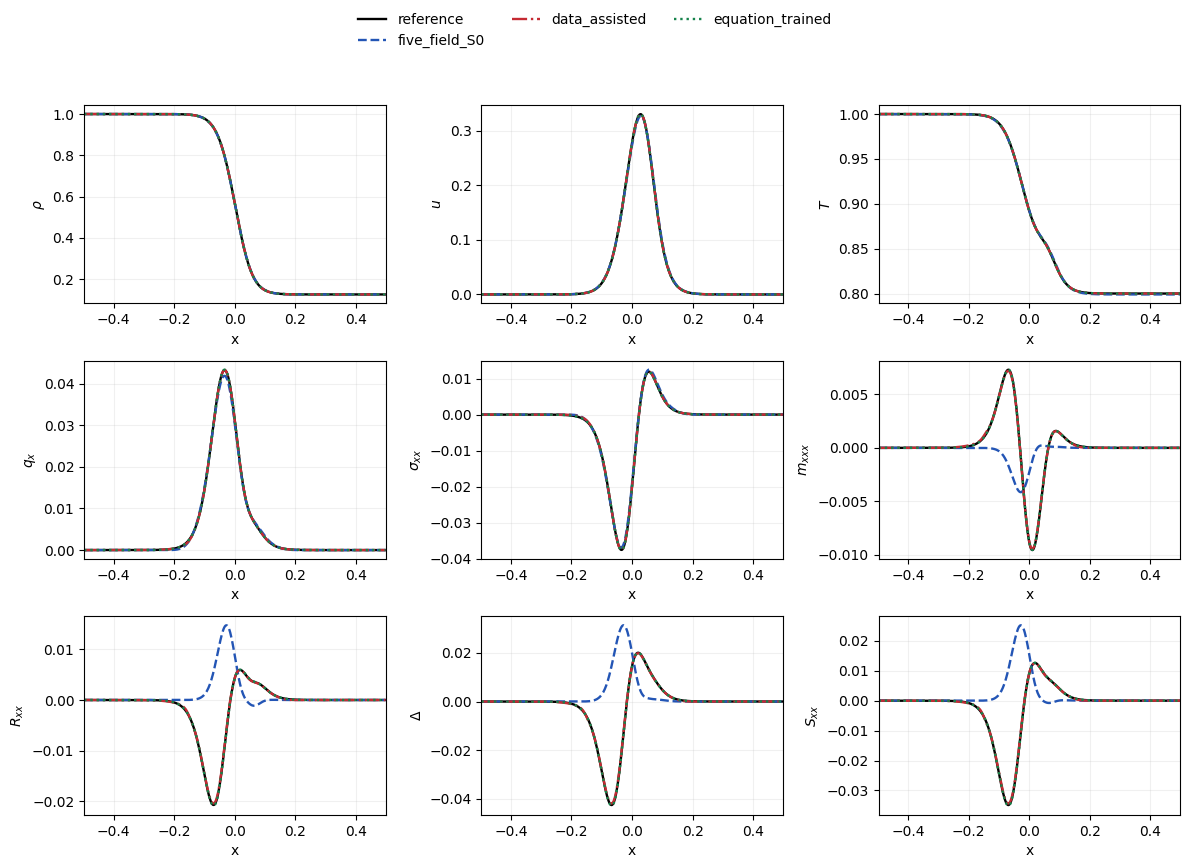

In [13]:
supervised_ids = [c for c in ks.available_cases() if c.startswith('supervised')]
assert len(supervised_ids)==1
supervised = ks.load_case(supervised_ids[0])
print('Table G: one declared reference/grid for every method')
table_G = score_profiles(supervised).pivot(index='field',columns='method',values='E_percent')
display(table_G)
print('Case/data-role metadata:')
display(supervised.metadata)
plot_profiles(supervised)

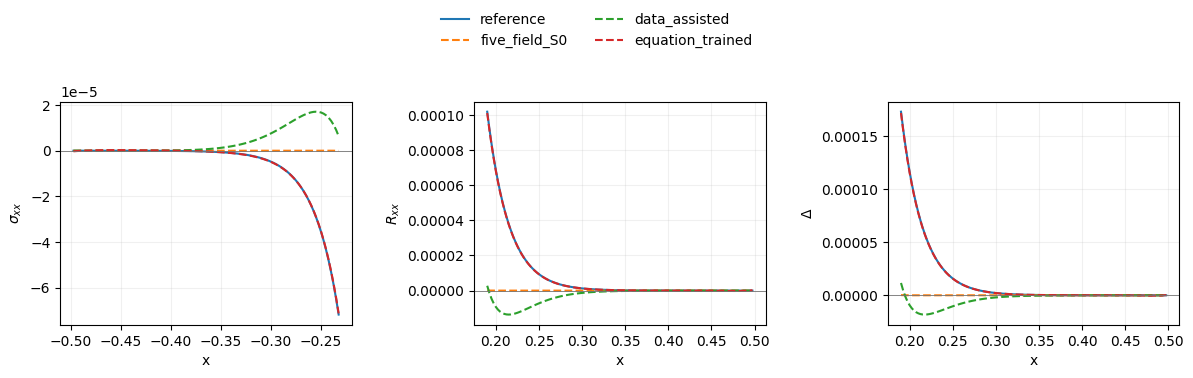

These are source-discussed tail regions, not newly selected independent test sets.
Elapsed Run All CPU wall time in this environment (includes plotting/imports): 103.06 s


In [14]:
# Compare signed quantities at the actual comparison nodes; no fitted shift.
fig,axes = plt.subplots(1,3,figsize=(12,3.8))
for ax,field,interval in zip(axes,('sigma','R','Delta'),((-0.5,-0.23),(0.19,0.5),(0.19,0.5))):
    mask = (supervised.x>=interval[0]) & (supervised.x<=interval[1])
    for method in ['reference']+selected_methods(supervised):
        ax.plot(supervised.x[mask],supervised.field(method,field)[mask],label=method,
                lw=1.5,ls='-' if method=='reference' else '--')
    ax.axhline(0,color='0.45',lw=.6)
    ax.set(xlabel='x',ylabel=FIELD_LABELS[field]); ax.grid(alpha=.18)
fig.legend(*axes[0].get_legend_handles_labels(),loc='upper center',ncol=2,frameon=False)
fig.tight_layout(rect=(0,0,1,.82)); plt.show()
print('These are source-discussed tail regions, not newly selected independent test sets.')
print('Elapsed Run All CPU wall time in this environment (includes plotting/imports):',
      round(time.perf_counter()-START,2),'s')

## 9. Submit a reproducible numerical investigation

Keep a copy of the notebook and change only the stated controls. Include
parameters, measured tables, physical profiles and an interpretation for
every exercise. A neural method is allowed to lose.

1. **Jump conditions - Table B.** Use $M=1.5,2,3$ separately. Report both
   endpoint states and the three flux differences. Deliberately omit
   $u\sigma$ when evaluating the saved Mach-2 interior, plot the resulting
   energy defect, then restore the correct formula. Explain why endpoints
   alone cannot reveal that mistake.
2. **Moment information - Table C.** Recover $R_B=-2/3$, $\Delta_B=2$ and
   $S_A=S_B=0$. Repeat at orders 12, 24 and 64. Explain why supervising
   lower moments or $S$ cannot uniquely determine separate $R,\Delta$.
3. **Quadrature and model physics - Table D.** At cutoff 8, compare orders
   12, 20 and 32; at order 32 compare cutoffs 4, 6 and 8. Report density/
   heat-flux errors, invariant defects, negative-target mass and runtime.
   Then change $\Pr$ from 1 to $2/3$ at fixed quadrature. Check the measured
   stress and heat-flux rates against their analytic laws.
4. **Transient model comparison - Table E.** For each collision model,
   compare parent and final errors in all nine columns. Plot the signed
   $q,\sigma,R,\Delta$ discrepancies versus $x$. Identify the region of
   largest absolute error. Explain the significance of $t_f/\tau=0.02$;
   do not compare the two models against a swapped reference.
5. **Optimization and seeds - Table F.** Inspect all three seeds. Quantify
   the mean change from SSB to split-half SSB for heat flux and stress.
   State the improvement and regression separately. Use the flux plot to
   explain why passing conservation does not imply an accurate profile.
6. **Density thickness.** For one retained stationary Mach-2 stage, compute
   $\delta_\rho=(\rho_2-\rho_1)/\max|d\rho/dx|$ using `np.gradient(rho,x)`.
   Repeat on every second and fourth retained node, and on the matched
   DVM. Label this as sampling/derivative sensitivity, not a fresh DVM
   grid-refinement study. Never combine different Mach numbers in one plot.
7. **Supervision and tails - Table G.** Compare all three methods against
   the same DVM, globally and over the stated tail intervals. Report
   relative L2 plus a signed discrepancy normalized by the full-reference
   maximum magnitude. Identify wrong signs and retained failed admission
   checks. List which reference information entered fitting, scaling and
   selection; removing observed positions is not enough to establish a
   new held-out test.

**Assessment:** numerical setup and measured tables (35%), correct signed
physical profiles (25%), interpretation of information/physics limits (30%),
and reproducible environment/source identifiers (10%). No credit depends
on beating a classical reference or making a failed gate pass.

**Sources:** [paper v2](https://arxiv.org/abs/2605.29211v2),
[pinned PINNs-DVM repository](https://github.com/Ehsan-Roohi/PINNs-DVM/tree/add5388f7da5f7eace95fff97d34d6ed58b90169),
[extract provenance and reuse notice](../../data/week10_2_kinetic_shock/README.md).